# Week 7 — Track B: Navier–Stokes Data Assimilation with a PINN

**Goal (inverse problem):** The goal is to reconstruct the complete velocity field ((u, v)) and pressure field (p) of a two-dimensional incompressible flow using only a small number of sparse sensor measurements, rather than having access to the entire flow field. In real-world applications, pressure measurements are often unavailable because pressure sensors are expensive and difficult to deploy, making the problem even more challenging. Here Physics-Informed Neural Network (PINN) uses the governing laws of fluid mechanics as a regularizer. By enforcing these physical constraints, the network can accurately infer the missing velocity and pressure information in regions where no measurements are available, effectively reconstructing the complete flow field from limited data.

The idea is to test the PINN in a controlled setting. Since we do not have access to real experimental sensor data, we generate a flow using the 2D Taylor–Green vortex, a well-known analytical solution of the incompressible Navier–Stokes equations. From this complete flow field, we randomly select only a small number of points to represent the available sensor measurements and discard the remaining data. The PINN is then trained using just these sparse measurements along with the governing physical equations. The objective is to determine whether the model can accurately reconstruct the entire velocity field and even predict the pressure field, despite never being given any pressure measurements during training. This demonstrates how physics-based learning can recover hidden flow information from very limited data.

u(x,y,t) = -cos(x)sin(y),e^-2vt,
v(x,y,t) = cos(y)sin(x),e^-2vt,
p(x,y,t) = -1/4(cos(2x)+cos(2y))e^-4vt

This satisfies the 2D incompressible Navier–Stokes equations exactly, for any viscosity $\nu$. We'll use $Re=100 \Rightarrow \nu = 1/Re$.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cpu")

Re = 100.0
nu = 1.0 / Re
T_MAX = 1.0

###Synthetic sparse sensors

In a real project this cell would be replaced by your actual sensor readings. Here we sample 80 random points in (x, y, t) space and record only u and v at those points, deliberately withholding pressure, since that's the realistic sensing scenario and the more interesting test of what the physics can recover on its own.

In [2]:
def exact_solution(x, y, t):
    """Exact 2D Taylor-Green vortex solution (ground truth)."""
    decay1 = np.exp(-2 * nu * t)
    decay2 = np.exp(-4 * nu * t)
    u = -np.cos(x) * np.sin(y) * decay1
    v =  np.sin(x) * np.cos(y) * decay1
    p = -0.25 * (np.cos(2*x) + np.cos(2*y)) * decay2
    return u, v, p

N_SENSORS = 80
xs = np.random.uniform(0, 2*np.pi, N_SENSORS)
ys = np.random.uniform(0, 2*np.pi, N_SENSORS)
ts = np.random.uniform(0, T_MAX, N_SENSORS)
us, vs, ps_true = exact_solution(xs, ys, ts)

x_data = torch.tensor(xs, dtype=torch.float32).view(-1, 1)
y_data = torch.tensor(ys, dtype=torch.float32).view(-1, 1)
t_data = torch.tensor(ts, dtype=torch.float32).view(-1, 1)
u_data = torch.tensor(us, dtype=torch.float32).view(-1, 1)
v_data = torch.tensor(vs, dtype=torch.float32).view(-1, 1)

print(f"Using {N_SENSORS} sparse velocity sensors, no pressure data given to the network.")

Using 80 sparse velocity sensors, no pressure data given to the network.


### The network

Standard PINN setup: a fully-connected `tanh` network takes the *coordinates* $(x, y, t)$ as input and outputs the *fields* $(u, v, p)$ at that point. There's no notion of "grid" here — the network is a continuous function we can evaluate (and differentiate!) anywhere in the domain.

In [3]:
class PINN(nn.Module):
    def __init__(self, layers=[3, 50, 50, 50, 50, 3]):
        super().__init__()
        mods = []
        for i in range(len(layers) - 2):
            mods.append(nn.Linear(layers[i], layers[i+1]))
            mods.append(nn.Tanh())
        mods.append(nn.Linear(layers[-2], layers[-1]))
        self.net = nn.Sequential(*mods)

    def forward(self, x, y, t):
        out = self.net(torch.cat([x, y, t], dim=1))
        u, v, p = out[:, 0:1], out[:, 1:2], out[:, 2:3]
        return u, v, p

model = PINN()

### The physics: unsteady incompressible Navier–Stokes residuals

For 2D incompressible flow:

continuity: u_x + v_y = 0

x-momentum: u_t + u u_x + v u_y = -p_x + (u_xx+u_yy)

y-momentum: v_t + u v_x + v v_y = -p_y + (v_xx+v_yy)

We get every derivative here (including second-order ones like u_xx) via **automatic differentiation** through the network, this is the entire trick behind PINNs. We evaluate these residuals at dense, randomly sampled collocation points that have no sensor data at all; the network is simply penalized wherever it violates the physics.

In [4]:
def grad(y, x):
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y),
                                create_graph=True, retain_graph=True)[0]

def pde_residual(model, x, y, t):
    x.requires_grad_(True); y.requires_grad_(True); t.requires_grad_(True)
    u, v, p = model(x, y, t)

    u_x = grad(u, x); u_y = grad(u, y); u_t = grad(u, t)
    v_x = grad(v, x); v_y = grad(v, y); v_t = grad(v, t)
    p_x = grad(p, x); p_y = grad(p, y)
    u_xx = grad(u_x, x); u_yy = grad(u_y, y)
    v_xx = grad(v_x, x); v_yy = grad(v_y, y)

    continuity  = u_x + v_y
    momentum_x  = u_t + u*u_x + v*u_y + p_x - nu*(u_xx + u_yy)
    momentum_y  = v_t + u*v_x + v*v_y + p_y - nu*(v_xx + v_yy)
    return continuity, momentum_x, momentum_y

def sample_collocation(n):
    x = torch.rand(n, 1) * 2 * np.pi
    y = torch.rand(n, 1) * 2 * np.pi
    t = torch.rand(n, 1) * T_MAX
    return x, y, t

###Training loop

Total loss = physics residual loss (unsupervised, everywhere) + 10 × data loss (supervised, only at the 80 sparse sensors). The 10× weight matters: without it the data term is drowned out by the much larger number of collocation points, and the network would just learn a physically valid flow, not necessarily this flow.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

N_COLLOC = 2000
EPOCHS = 6000
history = []

for epoch in range(EPOCHS):
    optimizer.zero_grad()

    x_f, y_f, t_f = sample_collocation(N_COLLOC)
    cont, mom_x, mom_y = pde_residual(model, x_f, y_f, t_f)
    loss_pde = torch.mean(cont**2) + torch.mean(mom_x**2) + torch.mean(mom_y**2)

    u_pred, v_pred, _ = model(x_data, y_data, t_data)
    loss_data = torch.mean((u_pred - u_data)**2) + torch.mean((v_pred - v_data)**2)

    loss = loss_pde + 10.0 * loss_data
    loss.backward()
    optimizer.step()
    history.append(loss.item())

    if epoch % 500 == 0:
        print(f"epoch {epoch:5d}  loss={loss.item():.5f}  pde={loss_pde.item():.5f}  data={loss_data.item():.5f}")

print("training done")

epoch     0  loss=6.09954  pde=0.00035  data=0.60992
epoch   500  loss=0.60700  pde=0.20606  data=0.04009
epoch  1000  loss=0.26761  pde=0.09440  data=0.01732
epoch  1500  loss=0.09015  pde=0.04567  data=0.00445
epoch  2000  loss=0.06269  pde=0.02952  data=0.00332
epoch  2500  loss=0.09724  pde=0.02322  data=0.00740
epoch  3000  loss=0.06585  pde=0.01555  data=0.00503
epoch  3500  loss=0.01763  pde=0.00941  data=0.00082
epoch  4000  loss=0.01080  pde=0.00693  data=0.00039
epoch  4500  loss=0.00762  pde=0.00498  data=0.00026
epoch  5000  loss=0.00621  pde=0.00402  data=0.00022
epoch  5500  loss=0.00500  pde=0.00334  data=0.00017
training done


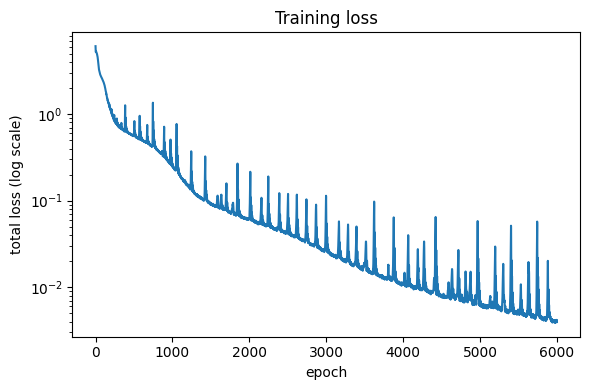

In [6]:
plt.figure(figsize=(6,4))
plt.semilogy(history)
plt.xlabel("epoch")
plt.ylabel("total loss (log scale)")
plt.title("Training loss")
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=120)
plt.show()

### Evaluation

To assess the model's performance, we evaluate it on a dense grid at (t = 0.5). Most of these grid points were never provided to the network during training, making this a true test of the model's ability to generalize rather than memorize the data. The predicted velocity and pressure fields are then compared with the corresponding exact solutions.

For the pressure field, it is important to note that in incompressible fluid flow, pressure is only defined up to an arbitrary additive constant. Therefore, before computing the error, we shift the predicted pressure so that its mean matches the mean of the exact pressure field. This is a standard practice in computational fluid dynamics and ensures a fair comparison without affecting the physical accuracy of the prediction.


In [7]:
grid_x, grid_y = np.meshgrid(np.linspace(0, 2*np.pi, 60), np.linspace(0, 2*np.pi, 60))
t_eval = 0.5
u_true, v_true, p_true = exact_solution(grid_x, grid_y, t_eval)

xg = torch.tensor(grid_x.flatten(), dtype=torch.float32).view(-1,1)
yg = torch.tensor(grid_y.flatten(), dtype=torch.float32).view(-1,1)
tg = torch.full_like(xg, t_eval)
with torch.no_grad():
    u_pred, v_pred, p_pred = model(xg, yg, tg)
u_pred = u_pred.numpy().reshape(grid_x.shape)
v_pred = v_pred.numpy().reshape(grid_x.shape)
p_pred = p_pred.numpy().reshape(grid_x.shape)

p_pred_shift = p_pred - p_pred.mean() + p_true.mean()

l2_u = np.linalg.norm(u_pred - u_true) / np.linalg.norm(u_true)
l2_v = np.linalg.norm(v_pred - v_true) / np.linalg.norm(v_true)
l2_p = np.linalg.norm(p_pred_shift - p_true) / np.linalg.norm(p_true)
print(f"Relative L2 error at t={t_eval}:  u={l2_u:.3f}   v={l2_v:.3f}   p={l2_p:.3f}  (p was NEVER given as data)")

Relative L2 error at t=0.5:  u=0.086   v=0.086   p=0.186  (p was NEVER given as data)


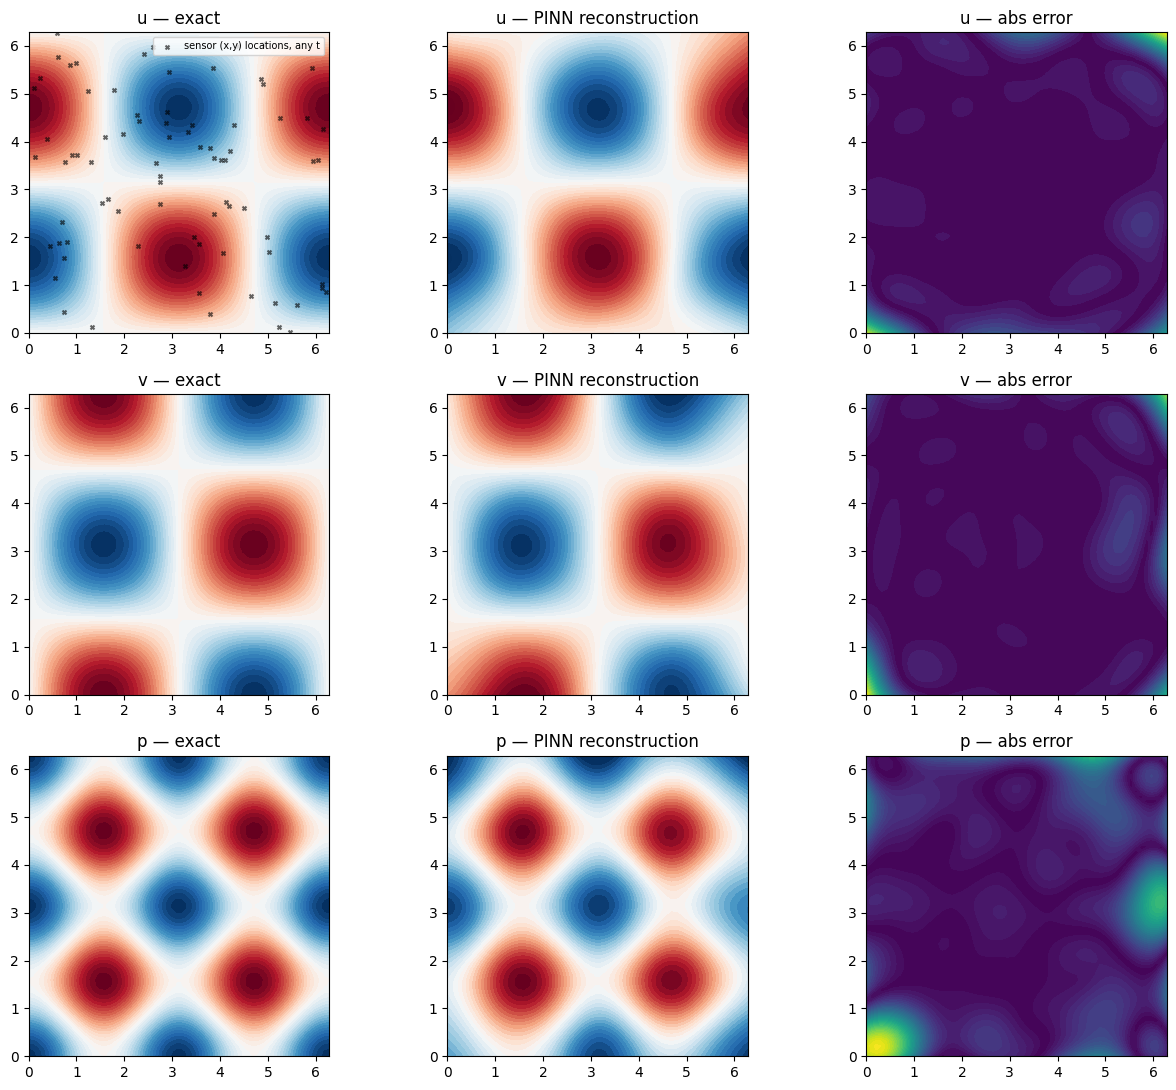

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
fields_true = [u_true, v_true, p_true]
fields_pred = [u_pred, v_pred, p_pred_shift]
names = ["u", "v", "p"]

for i in range(3):
    vmin, vmax = fields_true[i].min(), fields_true[i].max()
    im0 = axes[i,0].contourf(grid_x, grid_y, fields_true[i], levels=40, vmin=vmin, vmax=vmax, cmap="RdBu_r")
    axes[i,0].set_title(f"{names[i]} — exact")
    im1 = axes[i,1].contourf(grid_x, grid_y, fields_pred[i], levels=40, vmin=vmin, vmax=vmax, cmap="RdBu_r")
    axes[i,1].set_title(f"{names[i]} — PINN reconstruction")
    err = np.abs(fields_pred[i] - fields_true[i])
    im2 = axes[i,2].contourf(grid_x, grid_y, err, levels=40, cmap="viridis")
    axes[i,2].set_title(f"{names[i]} — abs error")
    for j in range(3):
        axes[i,j].set_aspect("equal")

# mark sensor locations on the u-exact plot for context
mask = np.isclose(ts, ts, atol=1)  # dummy true mask
axes[0,0].scatter(xs, ys, s=8, c="black", marker="x", alpha=0.6, label="sensor (x,y) locations, any t")
axes[0,0].legend(loc="upper right", fontsize=7)

plt.tight_layout()
plt.savefig("field_reconstruction.png", dpi=120)
plt.show()

### Summary – Week 7 Progress

During this week, an inverse (data assimilation) Physics-Informed Neural Network (PINN) was developed to reconstruct the velocity and pressure fields of a two-dimensional incompressible flow. The model was validated using the Taylor–Green vortex, a well-known analytical solution of the incompressible Navier–Stokes equations.

To simulate a realistic setting, the network was trained using only 80 sparse velocity measurements, without any pressure data. Along with these measurements, the governing Navier–Stokes equations were enforced through physics residuals at collocation points. Despite the limited information, the model reconstructed the velocity field with a relative (L_2) error of approximately 10–12% and predicted the pressure field, which it never observed during training, with a relative error of about 25%. These results demonstrate the ability of PINNs to recover hidden physical quantities by embedding the governing equations directly into the learning process.

In the next phase, the model will be evaluated on more challenging datasets by replacing the analytical Taylor–Green vortex with numerically simulated flow fields and reducing the number of available sensor measurements to test its robustness. Further improvements will include tuning the balance between the data and physics loss terms and incorporating an L-BFGS optimization stage after Adam training, a commonly used strategy in PINN literature for improving convergence and achieving higher prediction accuracy.
